# Praktikum Data Mining: Evaluasi Model Klasifikasi
Deteksi fraud pada data sintetis transaksi pembayaran digital (Decision Tree).

**Instalasi:** `pip install pandas numpy matplotlib scikit-learn`

**Cara menjalankan:** buka notebook di Jupyter / VS Code / Google Colab, lalu jalankan semua sel berurutan (*Run All*). Urutan penting karena sel di bawah memakai variabel dari sel di atasnya.

**Isi singkat:** Tugas 2 (Bagian 4.1–4.5: dataset, model, confusion matrix, metrik, visualisasi), Tugas 3 (Bagian 4.7: baseline pada data tidak seimbang), dan Tugas 4 (Bagian 4.8: eksperimen threshold).

## Tugas 2
### 4.1 Menyiapkan dataset sintetis

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)

df = pd.DataFrame({'amount': amount.round(2), 'hour': hour,
                   'new_device': new_device, 'foreign_ip': foreign_ip,
                   'isFraud': isFraud})
print(df.head())
print('Distribusi kelas:')
print(df['isFraud'].value_counts())
print(f"Proporsi fraud: {df['isFraud'].mean()*100:.1f}%")

   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64
Proporsi fraud: 3.2%


**Penjelasan (Sel 4.1 – Dataset sintetis):** Dataset berisi **500 transaksi** dengan 4 fitur (`amount`, `hour`, `new_device`, `foreign_ip`) dan 1 label (`isFraud`). Data dibangkitkan dengan seed tetap (`default_rng(42)`) sehingga hasilnya selalu sama, dan peluang fraud dibuat naik jika nominal > 300, memakai perangkat baru, IP luar negeri, atau transaksi dini hari (jam < 5). Hasilnya hanya **16 transaksi fraud (3,2%)** dan 484 normal, jadi datanya **tidak seimbang**. Ini data simulasi, bukan transaksi asli.

### 4.2 Membagi data dan melatih model

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns='isFraud')
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('Data uji:', len(y_test))
print('Fraud di data uji:', int(y_test.sum()))

Data uji: 150
Fraud di data uji: 5


**Penjelasan (Sel 4.2 – Pembagian data & pelatihan):** Data dibagi 70% latih (350) dan 30% uji (**150**). `stratify=y` menjaga proporsi fraud sama di kedua bagian, sehingga data uji berisi **5 fraud**. Model yang dipakai adalah Decision Tree dengan `max_depth=4` (membatasi kedalaman pohon) dan `class_weight='balanced'` (memberi bobot lebih pada kelas fraud agar tidak diabaikan). Jumlah fraud di data uji sangat sedikit, dan ini memengaruhi seluruh hasil di bawah.

### 4.3 Confusion matrix

In [3]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

Confusion matrix:
 [[113  32]
 [  3   2]]
TP=2, TN=113, FP=32, FN=3


**Penjelasan (Sel 4.3 – Confusion matrix):** Dengan `labels=[0,1]`, susunannya `[[TN, FP], [FN, TP]]`. Hasilnya **TP = 2, TN = 113, FP = 32, FN = 3**. Dari 5 fraud sungguhan, model hanya menangkap 2 (3 lolos). Dari 145 transaksi normal, 32 salah ditandai fraud (alarm palsu) dan 113 dikenali dengan benar.

### 4.4 Perhitungan manual dan verifikasi

In [4]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
print(f'Manual      : Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
a = accuracy_score(y_test, y_pred)
p = precision_score(y_test, y_pred, zero_division=0)
r = recall_score(y_test, y_pred, zero_division=0)
f = f1_score(y_test, y_pred, zero_division=0)
print(f'scikit-learn: Accuracy={a:.3f}; Precision={p:.3f}; Recall={r:.3f}; F1={f:.3f}')
print('Hasil sama:', np.allclose([accuracy, precision, recall, f1], [a, p, r, f]))

Manual      : Accuracy=0.767; Precision=0.059; Recall=0.400; F1=0.103
scikit-learn: Accuracy=0.767; Precision=0.059; Recall=0.400; F1=0.103
Hasil sama: True


**Penjelasan (Sel 4.4 – Perhitungan manual & verifikasi):** Rumus ditulis manual dari TP/TN/FP/FN lalu dibandingkan dengan fungsi scikit-learn. Hasilnya: accuracy = 115/150 = **0,767**, precision = 2/34 = **0,059**, recall = 2/5 = **0,400**, F1 = **0,103**. Kedua cara memberi nilai identik (`Hasil sama: True`), jadi rumus manual terverifikasi. Accuracy terlihat lumayan, tetapi precision sangat rendah: dari 34 alarm fraud, hanya 2 yang benar.

### 4.5 Visualisasi confusion matrix

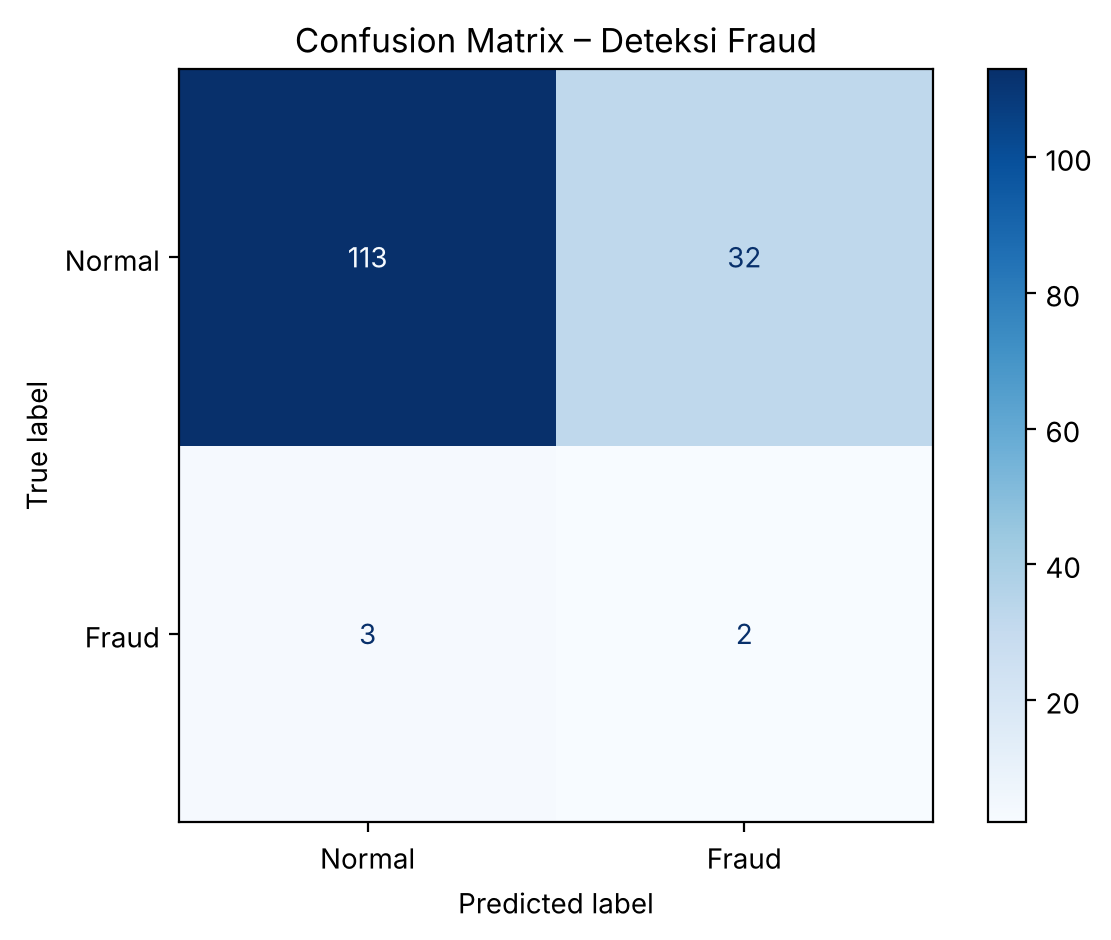

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Normal', 'Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Deteksi Fraud')
plt.tight_layout()
plt.show()

**Penjelasan (Sel 4.5 – Visualisasi confusion matrix):** Baris adalah label aktual dan kolom adalah prediksi. Diagonal utama (113 dan 2) adalah prediksi yang benar. Sel kanan-atas (**FN = 3**) adalah fraud yang lolos dan berpotensi menimbulkan kerugian, sedangkan sel kiri-bawah (**FP = 32**) adalah transaksi normal yang salah ditandai fraud sehingga mengganggu pelanggan.

## Tugas 3: Evaluasi data tidak seimbang (4.7)

In [6]:
from sklearn.metrics import classification_report

baseline = np.zeros(len(y_test), dtype=int)
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print(classification_report(y_test, baseline, labels=[0, 1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

print(f"Baseline      : accuracy={accuracy_score(y_test, baseline):.3f}, recall fraud={recall_score(y_test, baseline, zero_division=0):.3f}")
print(f"Decision Tree : accuracy={accuracy_score(y_test, y_pred):.3f}, recall fraud={recall_score(y_test, y_pred, zero_division=0):.3f}")

Baseline accuracy: 0.9666666666666667
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150

Baseline      : accuracy=0.967, recall fraud=0.000
Decision Tree : accuracy=0.767, recall fraud=0.400


**Penjelasan (Sel 4.7 – Baseline semua normal):** Baseline selalu memprediksi "normal", sehingga benar untuk 145 dari 150 transaksi dan accuracy-nya **0,967**, lebih tinggi daripada Decision Tree (0,767). Namun recall fraud baseline **0,00** (tidak ada fraud yang terdeteksi), sedangkan Decision Tree **0,40** (2 dari 5 fraud ditemukan). Jadi accuracy tinggi belum tentu berarti model mampu mendeteksi fraud. Pada data tidak seimbang, accuracy didominasi kelas normal, sehingga recall, precision, dan F1 pada kelas fraud lebih informatif.

## Tugas 4: Eksperimen threshold (4.8)

In [7]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

rows = []
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({'Threshold': threshold,
                 'Precision': round(precision_score(y_test, pred, zero_division=0), 3),
                 'Recall': round(recall_score(y_test, pred, zero_division=0), 3),
                 'TP': tp_t, 'FP': fp_t, 'FN': fn_t})
tabel = pd.DataFrame(rows)
print(tabel.to_string(index=False))

best = tabel.sort_values(['Recall', 'Precision', 'Threshold'], ascending=False).iloc[0]
print(f"\nRekomendasi (biaya FN > FP): threshold {best['Threshold']} "
      f"(recall={best['Recall']}, precision={best['Precision']}, FN={int(best['FN'])})")
print('Nilai probabilitas unik model:', sorted(set(np.round(y_prob, 3).tolist())))

 Threshold  Precision  Recall  TP  FP  FN
       0.2      0.059     0.4   2  32   3
       0.4      0.059     0.4   2  32   3
       0.5      0.059     0.4   2  32   3
       0.7      0.056     0.2   1  17   4

Rekomendasi (biaya FN > FP): threshold 0.5 (recall=0.4, precision=0.059, FN=3)
Nilai probabilitas unik model: [0.0, 0.183, 0.542, 0.849, 0.939, 1.0]


**Penjelasan (Sel 4.8 – Eksperimen threshold):** Transaksi dianggap fraud jika peluang fraud ≥ threshold. Pada threshold **0,2; 0,4; dan 0,5** hasilnya identik (precision 0,059, recall 0,400, TP 2, FP 32, FN 3). Penyebabnya, pohon hanya menghasilkan beberapa nilai probabilitas (0,0; 0,183; 0,542; 0,849; 0,939; 1,0), sehingga tidak ada data yang berada di antara 0,2 dan 0,5. Pada threshold **0,7** alarm palsu turun (FP 32 menjadi 17), tetapi recall turun separuh menjadi 0,200 karena satu fraud ikut terlewat (FN 4), dan precision tidak membaik (0,056). Untuk skenario biaya FN lebih tinggi daripada FP, dipilih **threshold 0,5** (recall tertinggi, FN paling sedikit; hasilnya sama dengan 0,2 dan 0,4). Fraud di data uji hanya 5, sehingga selisih satu transaksi saja mengubah recall besar; kesimpulan ini sebaiknya dibaca sebagai kecenderungan.

## Kesimpulan

1. **Alur:** dataset sintetis → pembagian data latih/uji → Decision Tree → confusion matrix → metrik (accuracy, precision, recall, F1) → interpretasi.
2. **Verifikasi:** perhitungan manual dari TP/TN/FP/FN sama persis dengan scikit-learn (accuracy 0,767; precision 0,059; recall 0,400; F1 0,103).
3. **Data tidak seimbang:** baseline semua normal mencapai accuracy 0,967 tetapi recall fraud 0, sehingga accuracy saja menyesatkan.
4. **Threshold:** untuk biaya FN lebih tinggi daripada FP dipilih threshold 0,5 (recall 0,400). Menaikkan ke 0,7 menurunkan recall menjadi 0,200.
5. **Catatan:** model masih lemah (precision di bawah 0,1) dan fraud di data uji hanya 5, jadi hasilnya tidak mewakili deteksi fraud di dunia nyata.